<a href="https://colab.research.google.com/github/katt-05/dl/blob/main/chapter05_fundamentals_of_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

In [2]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [3]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## Fundamentals of machine learning

### Generalization: The goal of machine learning

#### Underfitting and overfitting

##### Noisy training data

##### Ambiguous features

##### Rare features and spurious correlations

In [1]:
from keras.datasets import mnist
import numpy as np

(train_images, train_labels), _ = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28)) #1차원벡터로 변환
train_images = train_images.astype("float32") / 255 #픽셀 값 범위 0-255->0-1 정규화

train_images_with_noise_channels = np.concatenate(
    [train_images, np.random.random((len(train_images), 784))], axis=1
) #원본 이미지(784dim)에 무작위값인 동일차원 배열 옆으로 이어붙임
#1558차원 됨

train_images_with_zeros_channels = np.concatenate(
    [train_images, np.zeros((len(train_images), 784))], axis=1
) #원본 이미지(784dim)에 모든 값 0인 동일차원 배열 옆으로 이어붙임
#1558차원 됨

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [2]:
import keras
from keras import layers

def get_model():
    model = keras.Sequential(
        [
            layers.Dense(512, activation="relu"),#은닉층
            layers.Dense(10, activation="softmax"),#출력층
        ]
    )
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy", #정답 레이블 정수 형태로 되어있음
        metrics=["accuracy"],
    )
    return model

model = get_model() #새로운 모델 객체 생성
history_noise = model.fit( #무작위 잡음 포함 데이터셋 학습
    train_images_with_noise_channels, #원본+무작위잡음
    train_labels, #정답 데이터
    epochs=10,
    batch_size=128,
    validation_split=0.2,
)

model = get_model() #초기 상태 모델 설정
history_zeros = model.fit(
    train_images_with_zeros_channels, #값이 모두 0인 채널 포함 데이터셋
    #잡음 채널과 사이즈를 맞추기 위해 0을 추가한 데이터셋으로 설정
    train_labels,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8646 - loss: 0.4457 - val_accuracy: 0.9232 - val_loss: 0.2657
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9317 - loss: 0.2315 - val_accuracy: 0.9405 - val_loss: 0.2060
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9551 - loss: 0.1545 - val_accuracy: 0.9492 - val_loss: 0.1690
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9672 - loss: 0.1123 - val_accuracy: 0.9570 - val_loss: 0.1478
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9765 - loss: 0.0801 - val_accuracy: 0.9548 - val_loss: 0.1549
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9839 - loss: 0.0567 - val_accuracy: 0.9563 - val_loss: 0.1420
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9896 - loss: 0.0391 - val_accuracy: 0.9631 - val_loss: 0.1320
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9934 - loss: 0.0275 - val_accuracy: 0.

In [ ]:
# random noise : 이게 학습되면 모델이 잡음까지 외워버리는 과적합 발생
# 0인 noise랑 비교해서 의미 없는 잡음이 모델의 일반화 성능 얼마나 떨어뜨리는지 시각적으로 확인
#정보x상태, 가짜 정보(잡음) 있는 상태 다루는 방법 구분 가능

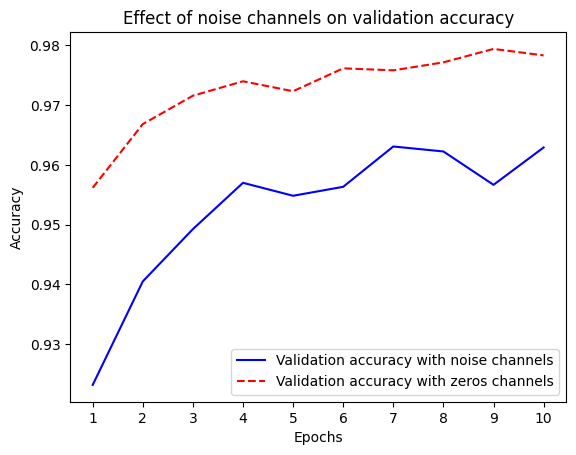

In [3]:
import matplotlib.pyplot as plt

val_acc_noise = history_noise.history["val_accuracy"]
val_acc_zeros = history_zeros.history["val_accuracy"]
epochs = range(1, 11)
plt.plot(
    epochs,
    val_acc_noise,
    "b-",
    label="Validation accuracy with noise channels",
)
plt.plot(
    epochs,
    val_acc_zeros,
    "r--",
    label="Validation accuracy with zeros channels",
)
plt.title("Effect of noise channels on validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()
#정확도 0채널>잡음채널

#### The nature of generalization in deep learning

In [5]:
(train_images, train_labels), _ = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28)) #2차원 이미지 1차원 벡터로 변환
train_images = train_images.astype("float32") / 255 #정규화

random_train_labels = train_labels[:] #복사본 저장
np.random.shuffle(random_train_labels) #이미지-정답 짝을 완전히 뒤섞음 = 잡음 주입

model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_images, #원본 이미지
    random_train_labels, #원본 이미지랑 맞지 않게 무작위로 뒤섞인 정답
    epochs=10,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1023 - loss: 2.3151 - val_accuracy: 0.1020 - val_loss: 2.3050
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1168 - loss: 2.3000 - val_accuracy: 0.1049 - val_loss: 2.3101
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1265 - loss: 2.2913 - val_accuracy: 0.1055 - val_loss: 2.3132
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1386 - loss: 2.2794 - val_accuracy: 0.1049 - val_loss: 2.3244
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1552 - loss: 2.2633 - val_accuracy: 0.1053 - val_loss: 2.3347
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1671 - loss: 2.2444 - val_accuracy: 0.1016 - val_loss: 2.3459
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1822 - loss: 2.2200 - val_accuracy: 0.1050 - val_loss: 2.3594
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1968 - loss: 2.1938 - val_accuracy: 0.

원본 이미지를 잘못된 정답(원본과 짝이 맞지 않게 무작위로 섞인 라벨)로 학습

-> 제대로 된 패턴 학습이 안됨

-> 패턴을 찾을 수 없음

-> 찍는 것과 비슷하게 나옴

-> accuracy 폭락 loss 폭등

##### The manifold hypothesis

##### Interpolation as a source of generalization

##### Why deep learning works

##### Training data is paramount

### Evaluating machine-learning models

#### Training, validation, and test sets

##### Simple hold-out validation

##### K-fold validation

##### Iterated K-fold validation with shuffling

#### Beating a common-sense baseline

#### Things to keep in mind about model evaluation

### Improving model fit

#### Tuning key gradient descent parameters

In [6]:
(train_images, train_labels), _ = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28)) #784 차원의 1차원 벡터로 변형
train_images = train_images.astype("float32") / 255  #정규화

model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1.0),
    #학습률 1 : 과도하게 큼 (보통 0.001  0.01 수준)
    #학습률 큼->모델이 오차를 줄이기 위해 가중치 수정 과정에서 과도하게 널뛰기
    #->최적의 값 못찾음 , 값 폭발
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_images, train_labels, epochs=10, batch_size=128, validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4077 - loss: 838.2783 - val_accuracy: 0.2583 - val_loss: 2.1925
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2554 - loss: 3.6748 - val_accuracy: 0.2098 - val_loss: 2.1573
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2320 - loss: 2.6317 - val_accuracy: 0.2297 - val_loss: 2.1379
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2365 - loss: 2.5576 - val_accuracy: 0.2259 - val_loss: 2.0705
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2382 - loss: 2.2967 - val_accuracy: 0.2408 - val_loss: 2.1306
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2395 - loss: 2.4598 - val_accuracy: 0.2952 - val_loss: 2.2573
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2441 - loss: 2.3037 - val_accuracy: 0.2518 - val_loss: 2.0229
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2426 - loss: 2.3347 - val_accuracy: 

 학습률 = 1 : 과도하게 큼 (보통 0.001  0.01 수준)


  학습률 큼->모델이 오차를 줄이기 위해 가중치 수정 과정에서 과도하게 널뛰기


  ->최적의 값 못찾음 , 값 폭발

  적절한 가중치 찾지 못해 정확도 폭락 손실 폭등

In [7]:
model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-2),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_images, train_labels, epochs=10, batch_size=128, validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9093 - loss: 0.3757 - val_accuracy: 0.9628 - val_loss: 0.1343
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9645 - loss: 0.1266 - val_accuracy: 0.9679 - val_loss: 0.1199
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9740 - loss: 0.0970 - val_accuracy: 0.9665 - val_loss: 0.1455
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9790 - loss: 0.0797 - val_accuracy: 0.9685 - val_loss: 0.1709
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9818 - loss: 0.0692 - val_accuracy: 0.9702 - val_loss: 0.1623
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9843 - loss: 0.0639 - val_accuracy: 0.9692 - val_loss: 0.2051
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9884 - loss: 0.0501 - val_accuracy: 0.9774 - val_loss: 0.1679
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9884 - loss: 0.0513 - val_accuracy: 0.

학습률= 0.01 : 적당함

정확도 높고 손실 적음

#### Using better architecture priors

#### Increasing model capacity

In [9]:
model = keras.Sequential([layers.Dense(10, activation="softmax")])
#은닉층 없이 출력층만 있는 구조->표현력 부족
model.compile(
    optimizer="rmsprop",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_small_model = model.fit(
    train_images, train_labels, epochs=20, batch_size=128, validation_split=0.2
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8359 - loss: 0.6657 - val_accuracy: 0.9032 - val_loss: 0.3572
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9026 - loss: 0.3537 - val_accuracy: 0.9141 - val_loss: 0.3102
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9118 - loss: 0.3179 - val_accuracy: 0.9189 - val_loss: 0.2934
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9158 - loss: 0.3019 - val_accuracy: 0.9226 - val_loss: 0.2837
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9184 - loss: 0.2924 - val_accuracy: 0.9232 - val_loss: 0.2792
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9208 - loss: 0.2855 - val_accuracy: 0.9235 - val_loss: 0.2763
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9211 - loss: 0.2808 - val_accuracy: 0.9260 - val_loss: 0.2723
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9225 - loss: 0.2766 - val_accuracy: 0.

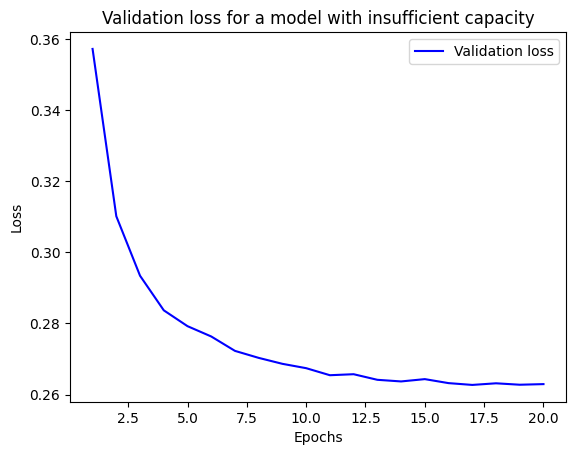

In [10]:
import matplotlib.pyplot as plt

val_loss = history_small_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(epochs, val_loss, "b-", label="Validation loss")
plt.title("Validation loss for a model with insufficient capacity")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
#로스 초반 급감 이후 완만하게 정체 (은닉층이 없어 생긴 과소적합 때문)

In [11]:
model = keras.Sequential(
    [
        layers.Dense(128, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_large_model = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9007 - loss: 0.3416 - val_accuracy: 0.9513 - val_loss: 0.1704
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9549 - loss: 0.1462 - val_accuracy: 0.9643 - val_loss: 0.1202
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9695 - loss: 0.1003 - val_accuracy: 0.9682 - val_loss: 0.1055
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9775 - loss: 0.0760 - val_accuracy: 0.9693 - val_loss: 0.0994
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9821 - loss: 0.0598 - val_accuracy: 0.9722 - val_loss: 0.0896
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9853 - loss: 0.0474 - val_accuracy: 0.9715 - val_loss: 0.0959
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9887 - loss: 0.0375 - val_accuracy: 0.9751 - val_loss: 0.0852
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9899 - loss: 0.0314 - val_accuracy: 0.

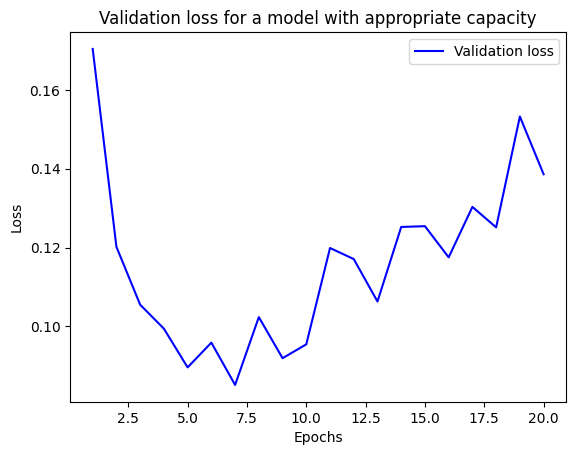

In [12]:
val_loss = history_large_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(epochs, val_loss, "b-", label="Validation loss")
plt.title("Validation loss for a model with appropriate capacity")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 에포크가 너무 커 val_loss 7 이후부터 올라가기 시작->가벼운 과소적합

In [13]:
model = keras.Sequential(
    [
        layers.Dense(2048, activation="relu"), #뉴런 너무 많음 ㅜㅜ->과적함
        layers.Dense(2048, activation="relu"),
        layers.Dense(2048, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_very_large_model = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=32, #배치 사이즈 너무 적음->과적합
    validation_split=0.2,
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9267 - loss: 0.2579 - val_accuracy: 0.9658 - val_loss: 0.1242
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9703 - loss: 0.1131 - val_accuracy: 0.9723 - val_loss: 0.1201
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9784 - loss: 0.0834 - val_accuracy: 0.9629 - val_loss: 0.1778
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9825 - loss: 0.0686 - val_accuracy: 0.9737 - val_loss: 0.1398
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9859 - loss: 0.0559 - val_accuracy: 0.9760 - val_loss: 0.1239
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9892 - loss: 0.0493 - val_accuracy: 0.9765 - val_loss: 0.1613
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9922 - loss: 0.0338 - val_accuracy: 0.9717 - val_loss: 0.2604
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9928 - loss: 0.0329

가중치 업데이트 횟수 = 전체 에포크 수 * 전체 데이터 수/배치 사이즈

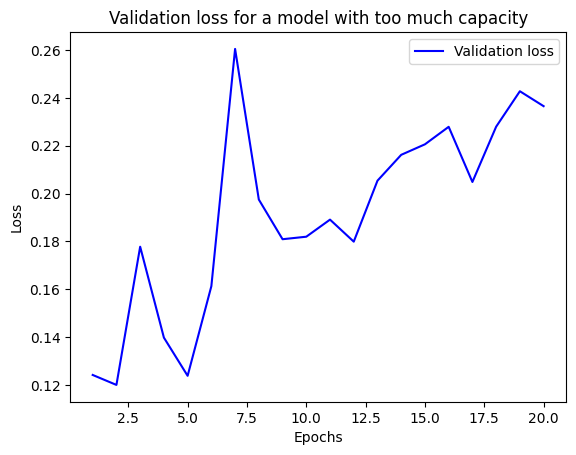

In [14]:
val_loss = history_very_large_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(epochs, val_loss, "b-", label="Validation loss")
plt.title("Validation loss for a model with too much capacity")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Improving generalization

#### Dataset curation

#### Feature engineering

#### Using early stopping

#### Regularizing your model

##### Reducing the network's size

In [15]:
from keras.datasets import imdb

(train_data, train_labels), _ = imdb.load_data(num_words=10000)

def vectorize_sequences(sequences, dimension=10000): #문장 속에 특정 단어 들어있으면 1,0으로 채움
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

train_data = vectorize_sequences(train_data)

model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy", #정답이 2진분류
    metrics=["accuracy"],
)
history_original = model.fit(
    train_data,
    train_labels,
    epochs=20,
    batch_size=512,
    validation_split=0.4, #검증 데이터 40프로
)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.7840 - loss: 0.5152 - val_accuracy: 0.8711 - val_loss: 0.3828
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8983 - loss: 0.3132 - val_accuracy: 0.8739 - val_loss: 0.3190
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9197 - loss: 0.2364 - val_accuracy: 0.8896 - val_loss: 0.2803
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9363 - loss: 0.1904 - val_accuracy: 0.8907 - val_loss: 0.2744
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9463 - loss: 0.1618 - val_accuracy: 0.8889 - val_loss: 0.2766
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9555 - loss: 0.1364 - val_accuracy: 0.8819 - val_loss: 0.2988
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9641 - loss: 0.1159 - val_accuracy: 0.8825 - val_loss: 0.3064
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accura

In [16]:
model = keras.Sequential(
    [
        layers.Dense(4, activation="relu"), #뉴런 갯수 4
        layers.Dense(4, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
history_smaller_model = model.fit(
    train_data,
    train_labels,
    epochs=20,
    batch_size=512,
    validation_split=0.4, #검증 데이터 40프로
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 155ms/step - accuracy: 0.6099 - loss: 0.6398 - val_accuracy: 0.6951 - val_loss: 0.5936
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.7563 - loss: 0.5574 - val_accuracy: 0.7263 - val_loss: 0.5487
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8232 - loss: 0.5076 - val_accuracy: 0.8493 - val_loss: 0.5120
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8629 - loss: 0.4702 - val_accuracy: 0.8178 - val_loss: 0.4914
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8871 - loss: 0.4391 - val_accuracy: 0.8504 - val_loss: 0.4698
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9073 - loss: 0.4114 - val_accuracy: 0.8584 - val_loss: 0.4556
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9215 - loss: 0.3862 - val_accuracy: 0.8665 - val_loss: 0.4405
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9341 - loss: 0.3593 - val_accuracy: 0.8746 - 

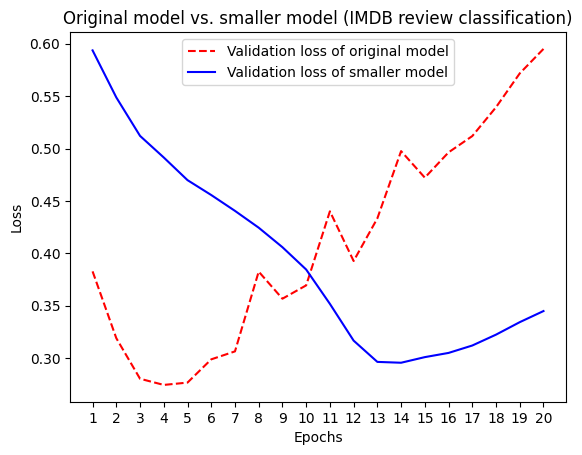

In [17]:
original_val_loss = history_original.history["val_loss"]
smaller_model_val_loss = history_smaller_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(
    epochs,
    original_val_loss,
    "r--",
    label="Validation loss of original model",
)
plt.plot(
    epochs,
    smaller_model_val_loss,
    "b-",
    label="Validation loss of smaller model",
)
plt.title("Original model vs. smaller model (IMDB review classification)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

4개 모델 : 용량이 작아서(과소적합) 정확도는 아쉽지만 과적합(val_loss)는 안일어남

16개모델: 초반 성능 뛰어나지만 에포크가 커서 과적합 찾아옴

In [18]:
model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"), #뉴런 512 너무 큼
        layers.Dense(512, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
history_larger_model = model.fit(
    train_data,
    train_labels,
    epochs=20,
    batch_size=512,
    validation_split=0.4,
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - accuracy: 0.7263 - loss: 0.5714 - val_accuracy: 0.8511 - val_loss: 0.3538
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.8652 - loss: 0.3278 - val_accuracy: 0.8759 - val_loss: 0.2960
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9091 - loss: 0.2299 - val_accuracy: 0.8803 - val_loss: 0.2859
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9293 - loss: 0.1826 - val_accuracy: 0.8695 - val_loss: 0.3208
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9493 - loss: 0.1345 - val_accuracy: 0.8812 - val_loss: 0.2904
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9692 - loss: 0.0914 - val_accuracy: 0.8866 - val_loss: 0.3259
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9744 - loss: 0.0808 - val_accuracy: 0.8859 - val_loss: 0.3481
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9788 - loss: 0.0697 - val_accuracy: 0.8846 - 

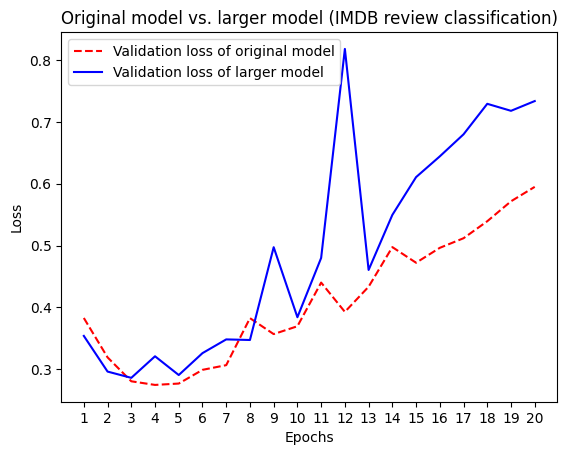

In [19]:
original_val_loss = history_original.history["val_loss"]
larger_model_val_loss = history_larger_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(
    epochs,
    original_val_loss,
    "r--",
    label="Validation loss of original model",
)
plt.plot(
    epochs,
    larger_model_val_loss,
    "b-",
    label="Validation loss of larger model",
)
plt.title("Original model vs. larger model (IMDB review classification)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show() #존나 과적합

##### Adding weight regularization

In [20]:
from keras.regularizers import l2

model = keras.Sequential(
    [
        layers.Dense(16, kernel_regularizer=l2(0.002), activation="relu"),
        layers.Dense(16, kernel_regularizer=l2(0.002), activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
    #kernel_regularizer=l2(0.002) : 가중치 너무 커지지 않도록(과적합 방지) 한계 부여
    #가중치가 커지려 하면 패널티 부여
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
history_l2_reg = model.fit(
    train_data,
    train_labels,
    epochs=20,
    batch_size=512,
    validation_split=0.4,
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.7782 - loss: 0.6230 - val_accuracy: 0.8538 - val_loss: 0.5021
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8896 - loss: 0.4230 - val_accuracy: 0.8543 - val_loss: 0.4371
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9097 - loss: 0.3483 - val_accuracy: 0.8847 - val_loss: 0.3739
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9197 - loss: 0.3127 - val_accuracy: 0.8756 - val_loss: 0.3806
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9304 - loss: 0.2875 - val_accuracy: 0.8757 - val_loss: 0.3868
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9344 - loss: 0.2730 - val_accuracy: 0.8798 - val_loss: 0.3718
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9378 - loss: 0.2656 - val_accuracy: 0.8860 - val_loss: 0.3610
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9438 - loss: 0.2517 - val_accuracy: 0.8820 - 

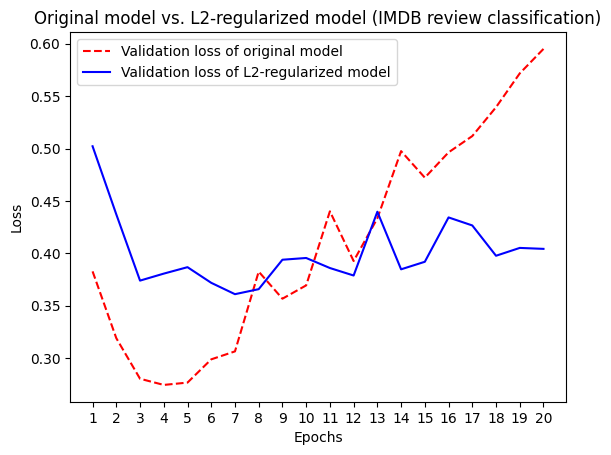

In [21]:
original_val_loss = history_original.history["val_loss"]
l2_val_loss = history_l2_reg.history["val_loss"]
epochs = range(1, 21)
plt.plot(
    epochs,
    original_val_loss,
    "r--",
    label="Validation loss of original model",
)
plt.plot(
    epochs,
    l2_val_loss,
    "b-",
    label="Validation loss of L2-regularized model",
)
plt.title(
    "Original model vs. L2-regularized model (IMDB review classification)"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()
#원본에 비해 과적합 덜함

In [22]:
from keras import regularizers

regularizers.l1(0.001) #수학적으로 중요하지 않은 가중치 0으로 만들어버림(특성선택)
regularizers.l1_l2(l1=0.001, l2=0.001) #복합

##### Adding dropout

In [23]:
model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.5),#은닉층의 뉴런 50프로를 무작위로 꺼버림->과적합 방지
        #드롭아웃 추가시 속도가 느려질 수 있음
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ]
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
history_dropout = model.fit(
    train_data,
    train_labels,
    epochs=20,
    batch_size=512,
    validation_split=0.4,
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - accuracy: 0.6122 - loss: 0.6518 - val_accuracy: 0.8374 - val_loss: 0.5551
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7257 - loss: 0.5537 - val_accuracy: 0.8651 - val_loss: 0.4392
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7943 - loss: 0.4651 - val_accuracy: 0.8737 - val_loss: 0.3599
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8337 - loss: 0.4055 - val_accuracy: 0.8830 - val_loss: 0.3222
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8658 - loss: 0.3514 - val_accuracy: 0.8884 - val_loss: 0.2935
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8817 - loss: 0.3112 - val_accuracy: 0.8902 - val_loss: 0.2786
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8995 - loss: 0.2793 - val_accuracy: 0.8902 - val_loss: 0.2785
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9061 - loss: 0.2532 - val_accuracy: 0.8875 - 

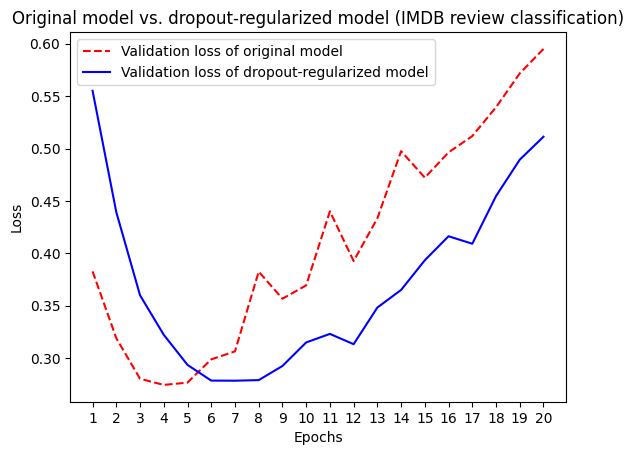

In [24]:
original_val_loss = history_original.history["val_loss"]
dropout_val_loss = history_dropout.history["val_loss"]
epochs = range(1, 21)
plt.plot(
    epochs,
    original_val_loss,
    "r--",
    label="Validation loss of original model",
)
plt.plot(
    epochs,
    dropout_val_loss,
    "b-",
    label="Validation loss of dropout-regularized model",
)
plt.title(
    "Original model vs. dropout-regularized model (IMDB review classification)"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()